# Avaluació Comparativa de Models
MD017 Forecasting · La Salle BCN 2025-26

Comparació sistemàtica de tots els models sobre el test set (2025). Mètriques: RMSE, MAE, MAPE, MASE.

> Prerequisit: executar tots els notebooks de models primer.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from features import TECNOLOGIES_MODELITZABLES
from plotting import format_ts_ax

DATA_DIR    = Path('../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']

## 1. Carregar tots els resultats


In [2]:
metric_files   = [f for f in RESULTS_DIR.glob('*_metrics.csv')
                  if f.name != 'all_metrics.csv'
                  and 'wfv' not in f.name]
forecast_files = [f for f in RESULTS_DIR.glob('*_forecasts.csv')
                  if 'wfv' not in f.name]
print(f'Fitxers de mètriques (backtest): {[f.name for f in metric_files]}')
print(f'Fitxers de forecasts (backtest): {[f.name for f in forecast_files]}')

all_metrics   = pd.concat([pd.read_csv(f) for f in metric_files],  ignore_index=True)
all_forecasts = pd.concat([pd.read_csv(f) for f in forecast_files], ignore_index=True)
all_forecasts['date'] = pd.to_datetime(all_forecasts['date'])

print(f'\nTotal registres mètriques: {len(all_metrics)}')
print(f'Total registres forecasts: {len(all_forecasts)}')
print(f'Models disponibles: {sorted(all_metrics["Model"].unique())}')

Fitxers de mètriques (backtest): ['baseline_metrics.csv', 'lgbm_metrics.csv', 'lstm_metrics.csv', 'sarima_metrics.csv', 'tbats_metrics.csv']
Fitxers de forecasts (backtest): ['baseline_forecasts.csv', 'lgbm_forecasts.csv', 'lstm_forecasts.csv', 'sarima_forecasts.csv', 'tbats_forecasts.csv']



Total registres mètriques: 49
Total registres forecasts: 588
Models disponibles: ['AutoSARIMA', 'ETS_Additiu', 'ETS_Multiplicatiu', 'LSTM', 'LightGBM', 'SeasonalNaive', 'TBATS']


## 2. Rànquing al Total (sèrie agregada)

Rànquing al holdout 2025 sobre la sèrie Total:


,RMSE,MAE,MAPE,MASE,Rànquing MASE
Model,,,,,
AutoSARIMA,463.95,363.42,4.59,0.42,1
ETS_Additiu,877.30,669.32,8.89,0.77,2
LSTM,1143.19,984.28,13.25,1.13,3
TBATS,1158.85,982.76,11.89,1.13,4
SeasonalNaive,2139.76,2034.58,25.44,2.34,5
LightGBM,2350.12,2056.62,24.12,2.37,6
ETS_Multiplicatiu,2448.58,2353.55,29.59,2.71,7


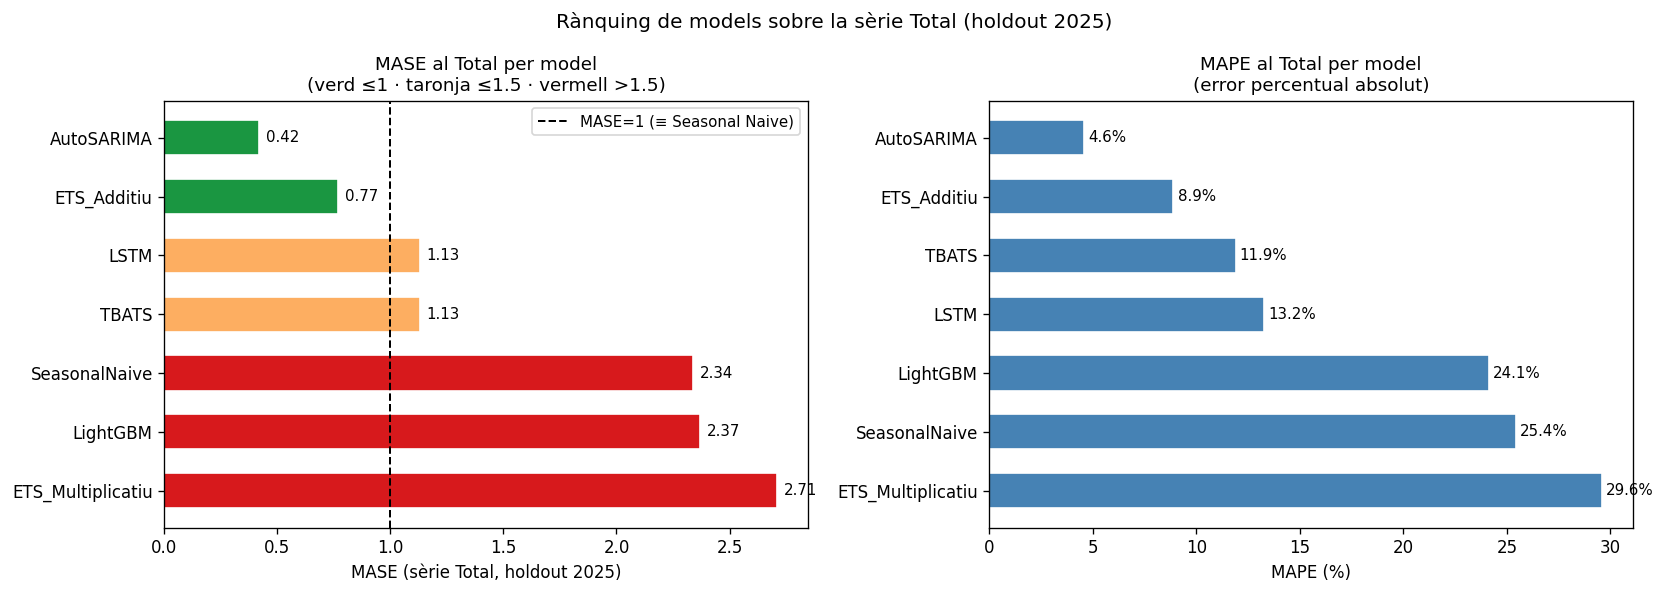

In [3]:
ranking_total = (
    all_metrics[all_metrics['Tecnologia'] == 'Total']
    .set_index('Model')[['RMSE', 'MAE', 'MAPE', 'MASE']]
    .round(2)
    .sort_values('MASE')
)
ranking_total['Rànquing MASE'] = range(1, len(ranking_total) + 1)
print('Rànquing al holdout 2025 sobre la sèrie Total:')
display(ranking_total)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors_mase = ['#1a9641' if v <= 1.0 else '#fdae61' if v <= 1.5 else '#d7191c'
               for v in ranking_total['MASE']]
axes[0].barh(ranking_total.index, ranking_total['MASE'],
             color=colors_mase, edgecolor='white', height=0.6)
axes[0].axvline(1.0, color='black', ls='--', lw=1.2, label='MASE=1 (≡ Seasonal Naive)')
axes[0].invert_yaxis()
axes[0].set_title('MASE al Total per model\n(verd ≤1 · taronja ≤1.5 · vermell >1.5)', fontsize=11)
axes[0].set_xlabel('MASE (sèrie Total, holdout 2025)')
axes[0].legend(fontsize=9)
for i, v in enumerate(ranking_total['MASE']):
    axes[0].text(v + 0.03, i, f'{v:.2f}', va='center', fontsize=9)

ranking_mape = ranking_total.sort_values('MAPE')
axes[1].barh(ranking_mape.index, ranking_mape['MAPE'],
             color='steelblue', edgecolor='white', height=0.6)
axes[1].invert_yaxis()
axes[1].set_title('MAPE al Total per model\n(error percentual absolut)', fontsize=11)
axes[1].set_xlabel('MAPE (%)')
for i, v in enumerate(ranking_mape['MAPE']):
    axes[1].text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)

plt.suptitle('Rànquing de models sobre la sèrie Total (holdout 2025)', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_17_model_ranking.png', bbox_inches='tight')
plt.show()

### Interpretació del rànquing al Total

El "número headline" del projecte és l'error sobre la sèrie Total: és la sèrie que sintetitza la demanda mensual catalana de vehicles electrificats. Hem entrenat un model independent per cada combinació (algorisme, sèrie), i la taula mostra com es comporta cada algorisme sobre el seu fit al Total. **No fem cap mitjana entre tecnologies**: avaluar el Total i avaluar les sub-tecnologies són dues preguntes diferents i les barregem en taules separades (secció 3).

Una clarificació del MASE abans de llegir: el MASE compara el MAE del model sobre el test amb el MAE in-sample del Seasonal Naive sobre el train (una constant per cada sèrie). Per això un MASE > 1 no vol dir que el model sigui pitjor que el SN avaluat sobre 2025 (el SN té MASE 2.34 al Total perquè el 2025 va ser un any difícil), sinó pitjor que el SN comportant-se sobre el seu propi entrenament. Per comparar models entre ells n'hi ha prou comparant els seus MASE de test.

**AutoSARIMA guanya clarament la sèrie Total** amb MASE 0.42, seguit d'ETS Additiu (0.77). Tots dos entrenen sobre el logaritme del Total (transformació recomanada per l'EDA amb BoxCox λ≈0.49), que estabilitza la variança creixent de l'agregat. La diferència respecte al tercer model (TBATS, 1.13) és substancial: la log-transformació importa més que la família del model en aquesta sèrie. ETS Multiplicatiu, malgrat ser bon model per a sèries amb estacionalitat creixent al nivell tecnologia, s'enfonsa al Total (MASE 2.71) perquè la suma de sis sèries amb dinàmiques heterogènies trenca l'estructura purament multiplicativa que aquest model assumeix.

### Comparació visual: sèrie Total

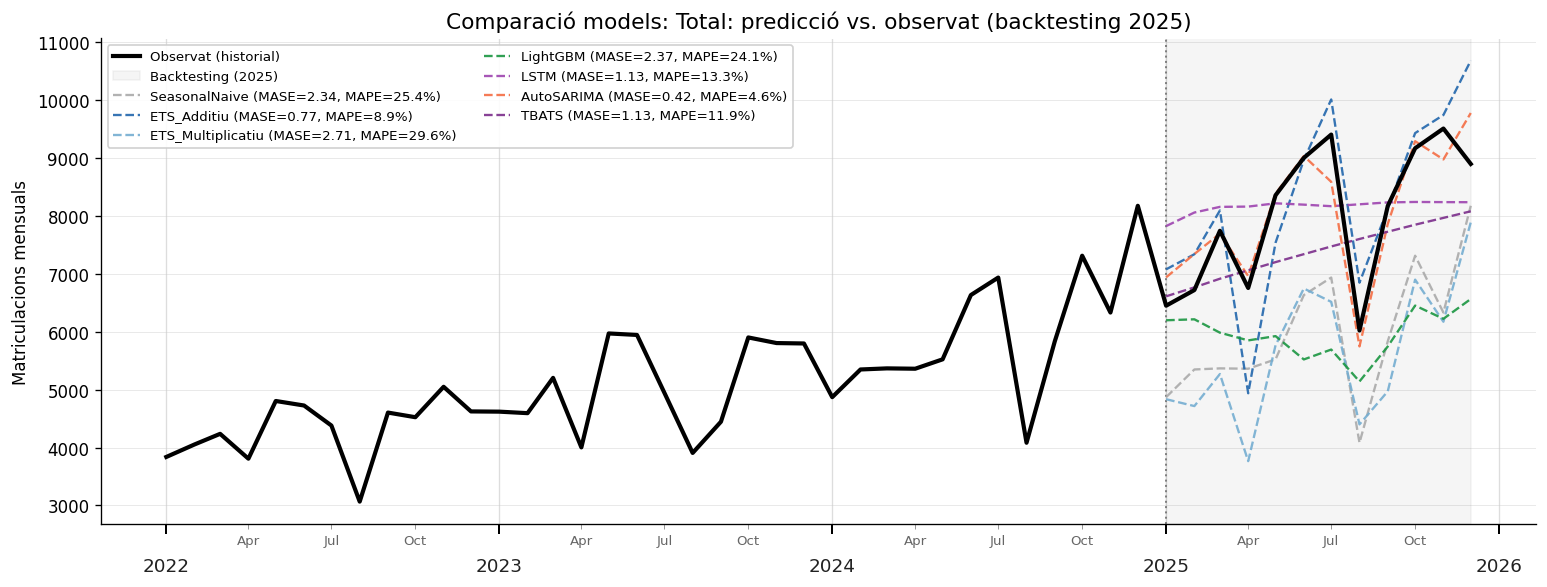

In [4]:
import matplotlib.dates as mdates

tech = 'Total'
sub = all_forecasts[all_forecasts['Tecnologia'] == tech].copy()

pivot_train_ev = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test_ev  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)

palette = {
    'SeasonalNaive':    '#aaaaaa',
    'ETS_Additiu':      '#2166ac',
    'ETS_Multiplicatiu':'#74add1',
    'AutoSARIMA':       '#f46d43',
    'LightGBM':         '#1a9641',
    'LSTM':             '#9e44b0',
    'TBATS':            '#7b2d8b',
}

fig, ax = plt.subplots(figsize=(13, 5))

y_train_plot = pivot_train_ev[tech].iloc[-36:]
y_test_plot  = pivot_test_ev[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='black', lw=2.5,
        label='Observat (historial)', zorder=10)

ax.axvspan(pivot_test_ev.index[0], pivot_test_ev.index[-1],
           alpha=0.08, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test_ev.index[0], color='gray', ls=':', lw=1.2)

for model_name in sub['Model'].unique():
    msub = sub[sub['Model'] == model_name].sort_values('date')
    row = all_metrics[(all_metrics['Model'] == model_name) &
                      (all_metrics['Tecnologia'] == tech)]
    if len(row):
        label = f"{model_name} (MASE={row['MASE'].values[0]:.2f}, MAPE={row['MAPE'].values[0]:.1f}%)"
    else:
        label = model_name
    ax.plot(msub['date'], msub['predicted'],
            color=palette.get(model_name, '#888888'),
            lw=1.4, ls='--', label=label, alpha=0.9)

ax.set_title(f'Comparació models: {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=8, loc='upper left', ncol=2, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_16_comparison_total.png', bbox_inches='tight')
plt.show()

La gràfica del Total il·lustra l'efecte directe de la transformació logarítmica. AutoSARIMA i ETS Additiu, els dos models que entrenen sobre el log del Total, obtenen els millors MASE (0.42 i 0.77) i les seves prediccions s'apropen molt bé tant al nivell com a la forma estacional de la sèrie real. La log-transformació estabilitza la variança creixent de l'agregat i, en tornar a l'escala original, permet recuperar pics i valls amb fidelitat.

TBATS i LSTM queden a un segon nivell (tots dos amb MASE 1.13): segueixen raonablement el nivell però suavitzen massa els pics de primavera i tardor i les valls d'agost. ETS Multiplicatiu (MASE 2.71) és el que s'allunya més als mesos de creixement fort, i Seasonal Naive (2.34) i LightGBM (2.37) tanquen la cua amb prediccions sense modulació estacional adequada. En conjunt, la figura confirma una lliçó concreta: per a una sèrie agregada amb tendència forta i variança creixent, escollir l'escala de modelització (log vs. nivell) pesa més que escollir entre famílies de models a igualtat d'altres factors.

## 3. Anàlisi per sub-tecnologia (6 sèries)

Aquí ens centrem només en les sis sub-tecnologies. La sèrie Total està coberta separadament a la secció 2.

### Mètriques per tecnologia (taula + bar-chart)


: Elèctric:


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Multiplicatiu,493.560000,403.550000,22.010000,1.220000
ETS_Additiu,493.840000,408.500000,21.880000,1.230000
AutoSARIMA,507.550000,453.760000,25.510000,1.370000
TBATS,561.010000,466.750000,24.700000,1.410000
LSTM,623.780000,527.970000,28.110000,1.600000
LightGBM,607.460000,544.890000,30.050000,1.650000
SeasonalNaive,674.400000,601.500000,34.340000,1.820000


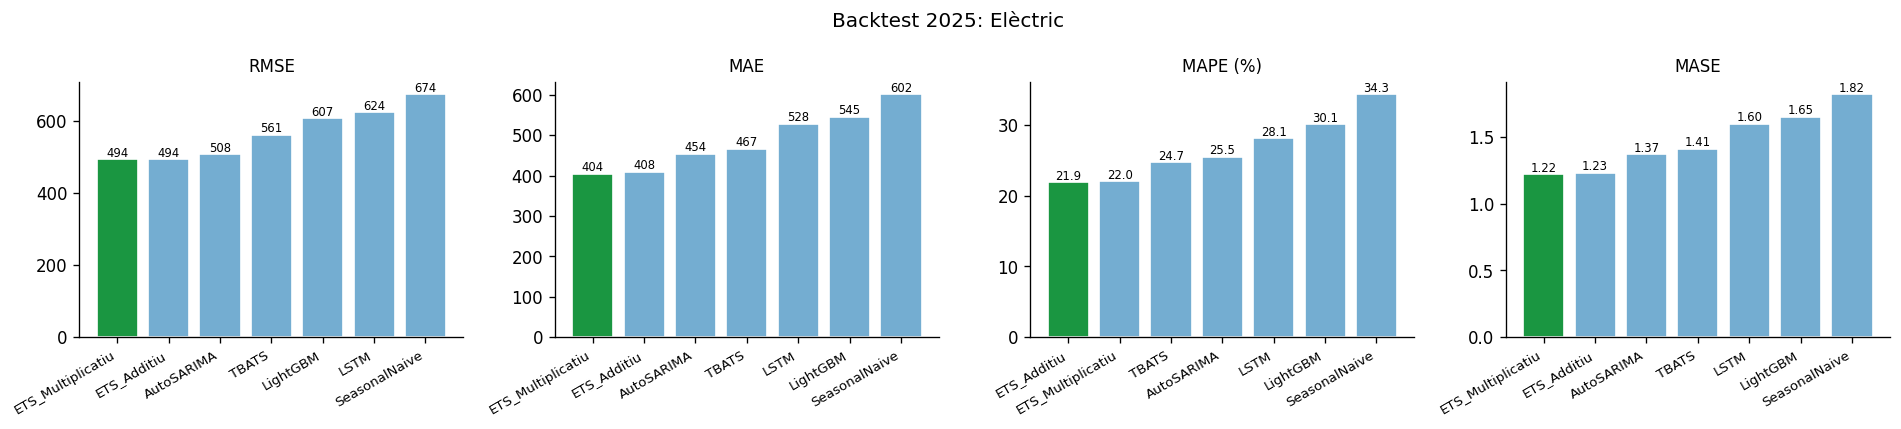


: Gasolina Mild Hybrid:


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,198.670000,146.310000,7.690000,0.560000
TBATS,234.530000,178.030000,9.400000,0.680000
ETS_Multiplicatiu,220.310000,186.850000,8.530000,0.720000
ETS_Additiu,279.930000,205.750000,10.970000,0.790000
LSTM,319.560000,264.040000,12.800000,1.010000
SeasonalNaive,446.720000,387.830000,18.050000,1.490000
LightGBM,441.600000,393.320000,17.580000,1.510000


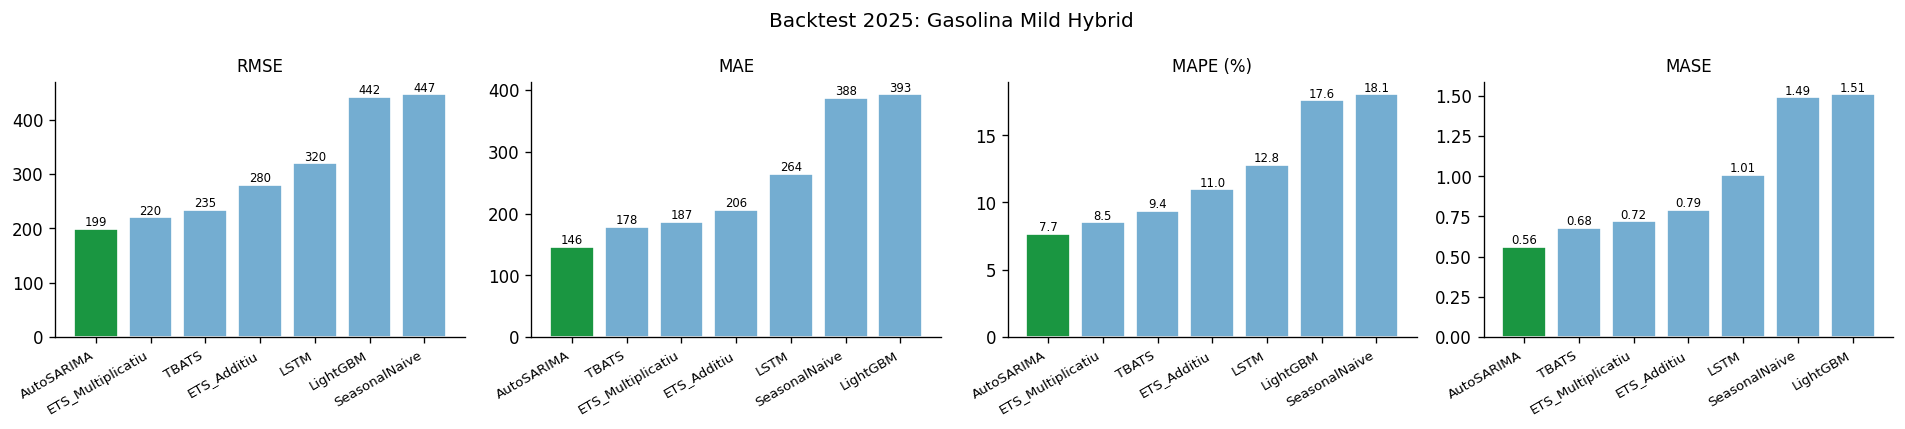


: Gasolina/Elèctric:


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Multiplicatiu,188.530000,157.740000,6.190000,0.550000
ETS_Additiu,211.900000,169.600000,7.180000,0.600000
AutoSARIMA,212.300000,170.510000,6.980000,0.600000
TBATS,246.970000,190.290000,8.230000,0.670000
LSTM,428.840000,366.660000,15.910000,1.290000
SeasonalNaive,455.430000,379.670000,15.060000,1.330000
LightGBM,605.910000,530.050000,19.920000,1.860000


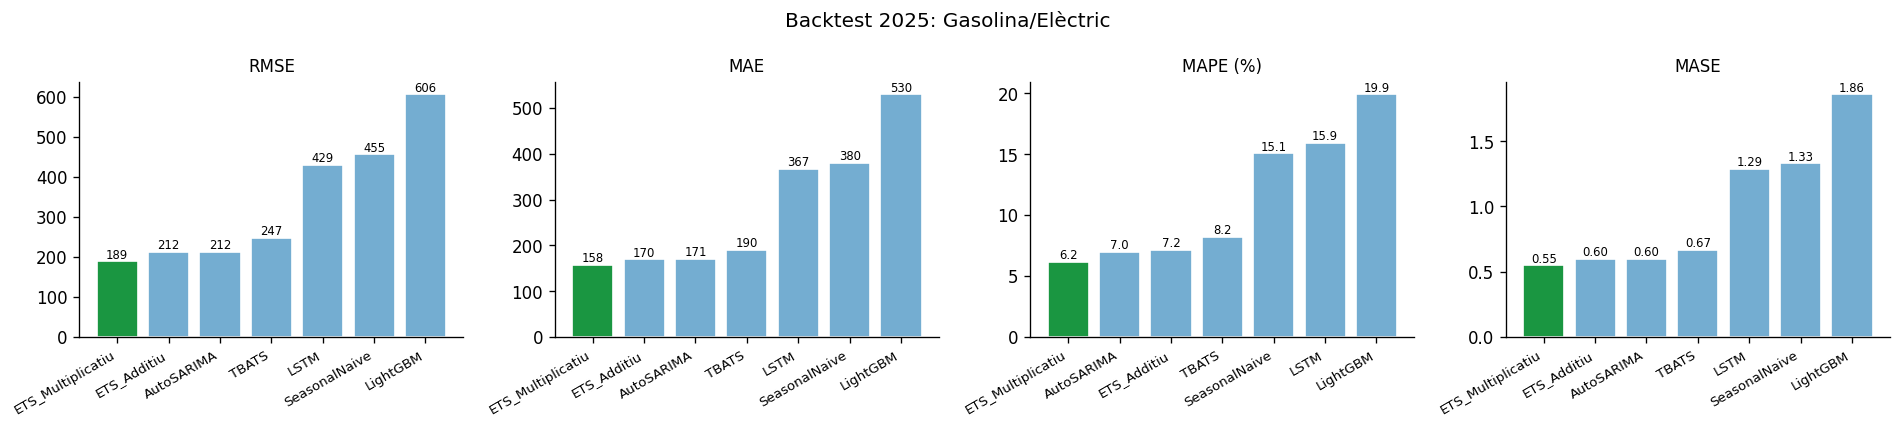


: Gasolina/Elèctric Endollable:


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,650.910000,580.040000,41.080000,4.500000
ETS_Additiu,658.590000,582.430000,40.890000,4.520000
TBATS,668.740000,599.200000,42.540000,4.650000
ETS_Multiplicatiu,685.590000,614.790000,43.770000,4.770000
LSTM,738.280000,648.510000,45.150000,5.030000
SeasonalNaive,724.480000,655.580000,47.100000,5.090000
LightGBM,731.460000,656.870000,46.570000,5.100000


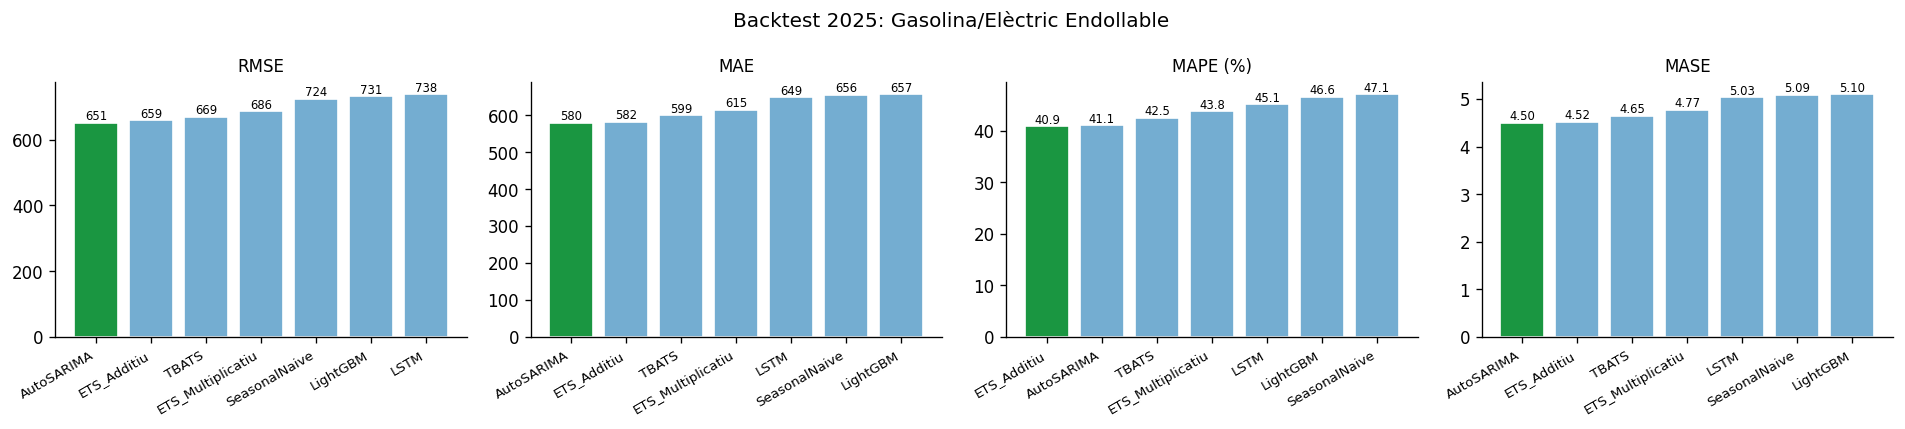


: Diesel Mild Hybrid:


,RMSE,MAE,MAPE,MASE
Model,,,,
LSTM,41.210000,32.540000,11.270000,0.530000
TBATS,40.040000,32.830000,11.690000,0.540000
AutoSARIMA,42.820000,34.330000,12.110000,0.560000
LightGBM,47.460000,36.660000,12.900000,0.600000
SeasonalNaive,54.920000,39.330000,13.060000,0.640000
ETS_Additiu,55.070000,44.900000,16.830000,0.740000
ETS_Multiplicatiu,57.220000,46.640000,16.670000,0.760000


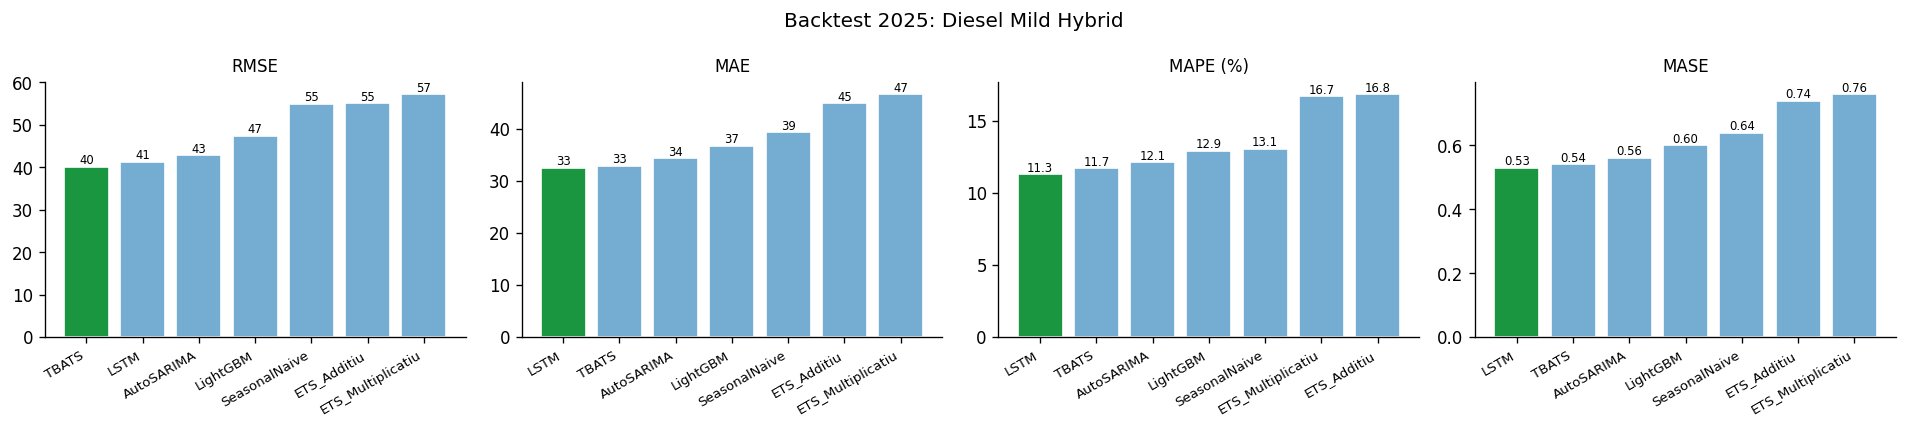


: Diesel/Elèctric Endollable:


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,16.000000,12.450000,28.900000,1.500000
ETS_Additiu,18.540000,13.850000,28.350000,1.670000
SeasonalNaive,19.480000,14.250000,28.350000,1.720000
LSTM,18.210000,14.790000,32.370000,1.790000
TBATS,21.230000,17.270000,35.570000,2.080000
LightGBM,27.450000,22.940000,48.000000,2.770000
ETS_Multiplicatiu,27.830000,23.710000,49.930000,2.860000


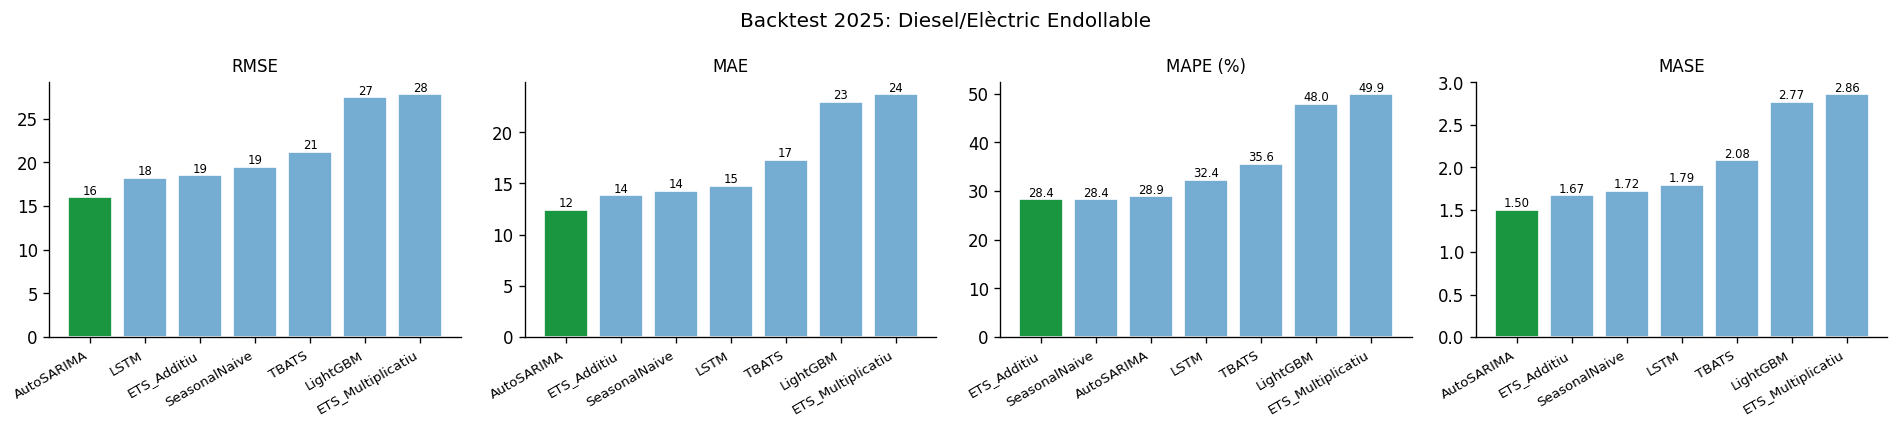

In [5]:
import re
METRICS_4 = ['RMSE', 'MAE', 'MAPE', 'MASE']
SUB_TECHS = [t for t in TECNOLOGIES if t != 'Total']

def slugify(s):
    s = re.sub(r'[^\w]+', '_', s.lower())
    return s.strip('_')

def per_tech_tables_and_bars(metrics_df, tag, save_prefix, suptitle_prefix):
    """Per cada sub-tecnologia: imprimeix taula (4 metrics, highlight min) i guarda bar-chart 1x4."""
    for letter, tech in zip('abcdef', SUB_TECHS):
        sub = (metrics_df[metrics_df['Tecnologia'] == tech]
               .set_index('Model')[METRICS_4].round(2)
               .sort_values('MASE'))
        if len(sub) == 0:
            continue
        print(f'\n: {tech}:')
        display(sub.style.highlight_min(axis=0, props='font-weight:bold; color:#1a9641'))

        fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
        for ax, metric in zip(axes, METRICS_4):
            order = sub[metric].sort_values().index.tolist()
            colors_bar = ['#1a9641' if i == 0 else '#74add1' for i in range(len(order))]
            ax.bar(range(len(order)), sub.loc[order, metric].values,
                   color=colors_bar, edgecolor='white')
            ax.set_xticks(range(len(order)))
            ax.set_xticklabels(order, rotation=30, ha='right', fontsize=8)
            ax.set_title(f'{metric}' + (' (%)' if metric == 'MAPE' else ''), fontsize=10)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            for i, v in enumerate(sub.loc[order, metric].values):
                ax.text(i, v, f'{v:.1f}' if metric == 'MAPE' else f'{v:.0f}' if metric in ('RMSE','MAE') else f'{v:.2f}',
                        ha='center', va='bottom', fontsize=7)
        plt.suptitle(f'{suptitle_prefix}: {tech}', fontsize=12)
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f'fig_{save_prefix}_{letter}_{slugify(tech)}.png',
                    bbox_inches='tight')
        plt.show()
        plt.close(fig)

per_tech_tables_and_bars(all_metrics, 'backtest', '15', 'Backtest 2025')

L'anàlisi per tecnologia és complementària al rànquing del Total: aquí no busquem el "millor model global", sinó entendre quina dinàmica afavoreix cada família de models. Cap model no guanya a totes les tecnologies alhora, i el patró té una lectura clara per dinàmica de la sèrie.

ETS Multiplicatiu és el millor a Elèctric (1.22) i Gasolina/Elèctric (0.55), les dues sèries on l'amplitud de l'estacionalitat creix proporcionalment al nivell — el supòsit del model encaixa amb el patró real. AutoSARIMA domina a Gasolina Mild Hybrid (0.56) i Diesel/Elèctric Endollable (1.50), tecnologies amb dinàmica més estable on l'estructura ARIMA captura bé la combinació de tendència + estacionalitat. **Una advertència important**: amb només 12 observacions de test, les diferències petites s'han de llegir com empats efectius. A Diesel Mild Hybrid el LSTM (0.53) queda per davant de TBATS (0.54) i AutoSARIMA (0.56) per centèsimes, sense significació pràctica. A Gasolina/Elèctric, AutoSARIMA (0.60) i ETS Additiu (0.60) també empaten.

Gasolina/Elèctric Endollable és el cas extrem: tots els models tenen MASE entre 4.50 i 5.10. No és una qüestió d'elecció de model, sinó d'informació no disponible al senyal univariant — la dinàmica regulatoria del MOVES III (data límit del 31-des-2024, pròrroga per Reial Decret-llei a l'abril) és el driver real i no apareix a la sèrie històrica. És el cas natural per a una extensió SARIMAX amb indicadors regulatoris com a regressors exògens.

### Sèries temporals individuals

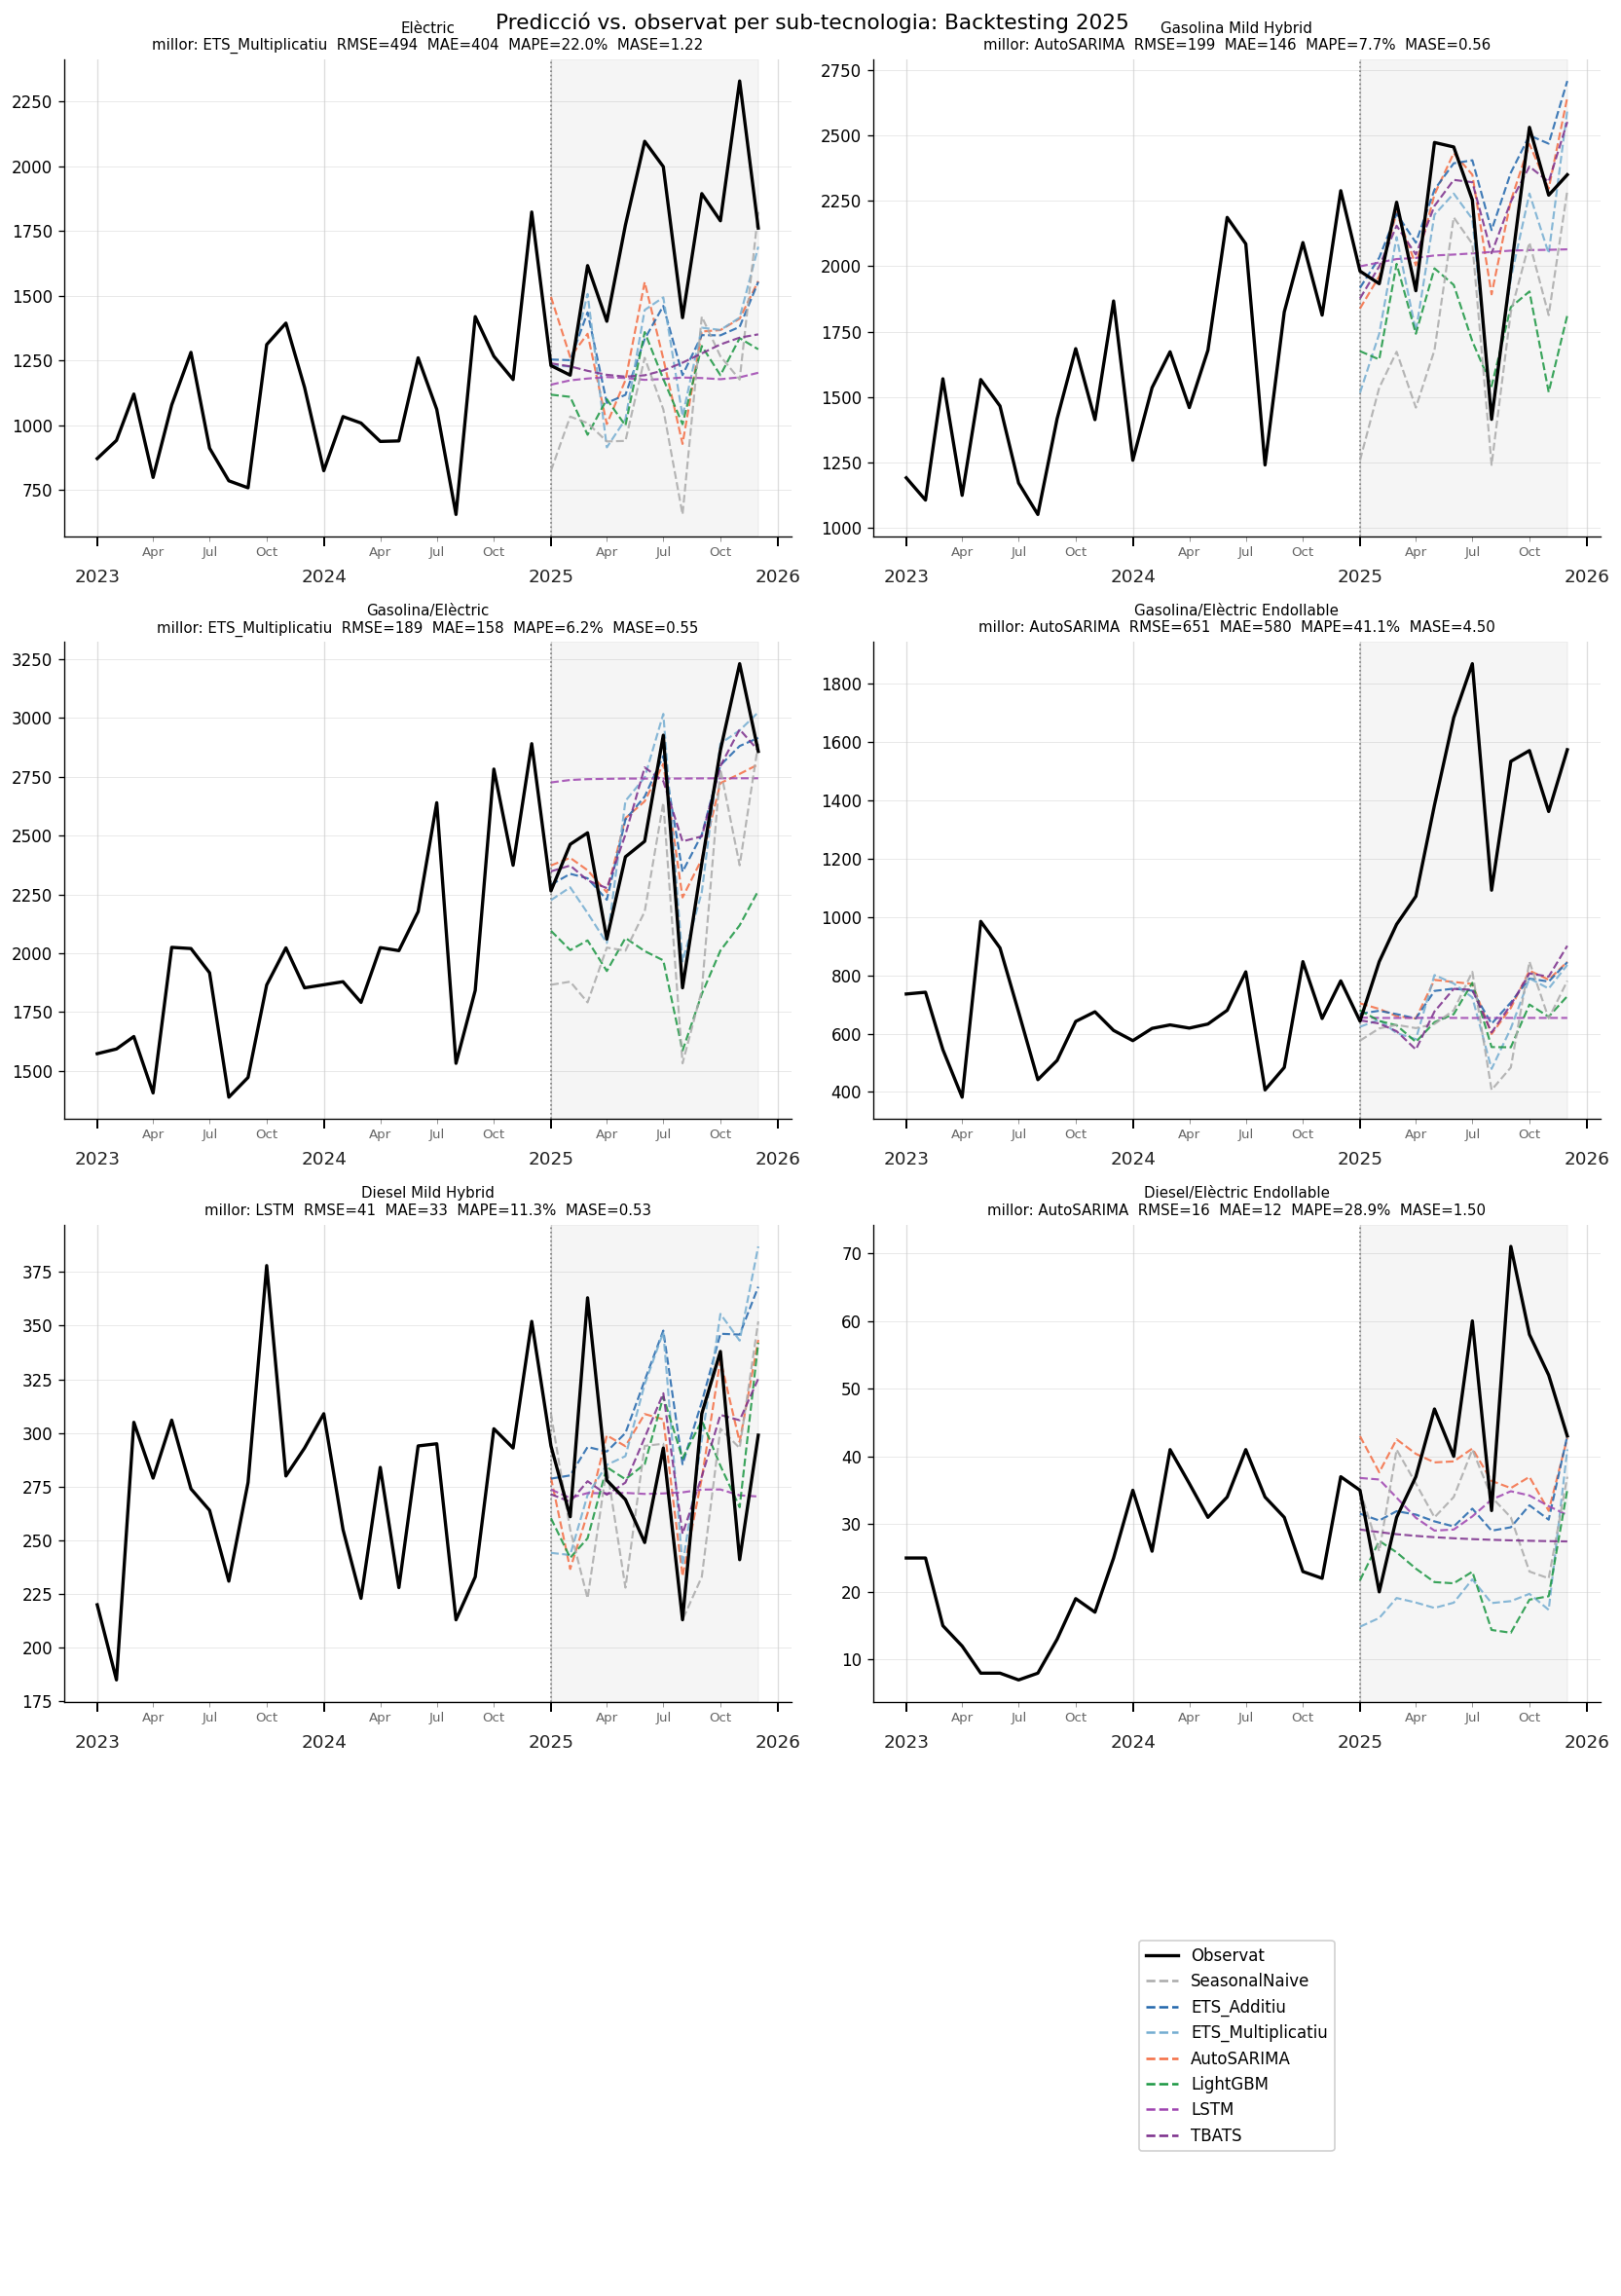

In [6]:
from matplotlib.lines import Line2D

# Sèries h=12 (backtest) per a cada sub-tecnologia (Total ja a fig_16_comparison_total.png)
best_idx = all_metrics.groupby('Tecnologia')['MASE'].idxmin()
best_per_tech = all_metrics.loc[best_idx].set_index('Tecnologia')

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes_flat = axes.flatten()

for i, tech in enumerate(SUB_TECHS):
    ax = axes_flat[i]
    sub_t = all_forecasts[all_forecasts['Tecnologia'] == tech]

    y_train_plot = pivot_train_ev[tech].iloc[-24:]
    y_test_plot  = pivot_test_ev[tech]
    observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
    observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)

    ax.plot(observed_dates, observed_vals, color='black', lw=2, zorder=10)
    ax.axvspan(pivot_test_ev.index[0], pivot_test_ev.index[-1], alpha=0.08, color='gray')
    ax.axvline(pivot_test_ev.index[0], color='gray', ls=':', lw=1)

    for model_name in sorted(sub_t['Model'].unique()):
        msub = sub_t[sub_t['Model'] == model_name].sort_values('date')
        ax.plot(msub['date'], msub['predicted'],
                color=palette.get(model_name, '#888888'),
                lw=1.3, ls='--', alpha=0.85)

    b = best_per_tech.loc[tech]
    ax.set_title(
        f'{tech}\nmillor: {b["Model"]}  RMSE={b["RMSE"]:.0f}  MAE={b["MAE"]:.0f}  '
        f'MAPE={b["MAPE"]:.1f}%  MASE={b["MASE"]:.2f}', fontsize=9)
    format_ts_ax(ax)

# Panells no usats (legend al darrer)
for j in range(len(SUB_TECHS), len(axes_flat)):
    axes_flat[j].axis('off')
legend_elements = [Line2D([0], [0], color='black', lw=2, label='Observat')]
for model_name, color in palette.items():
    legend_elements.append(Line2D([0], [0], color=color, lw=1.5, ls='--', label=model_name))
axes_flat[-1].legend(handles=legend_elements, loc='center', fontsize=10, framealpha=0.9)

plt.suptitle('Predicció vs. observat per sub-tecnologia: Backtesting 2025', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_18_comparison_per_tech.png', bbox_inches='tight')
plt.show()

La visualització per tecnologia permet veure d'una sola ullada per què el rànquing numèric queda com queda, i revela patrons que la taula de mètriques amaga.

Gasolina/Elèctric és la tecnologia on tots els models estadístics s'ajusten millor: l'estacionalitat és regular, la tendència és estable i les corbes de predicció s'agrupen prou a prop de la sèrie observada. ETS Multiplicatiu captura especialment bé els pics de primavera perquè l'amplitud de l'oscil·lació creix amb el nivell. Un patró similar apareix a Gasolina Mild Hybrid, on AutoSARIMA segueix de prop la sèrie amb el MASE més baix de tot el benchmark (0.56), i a Diesel Mild Hybrid, on les prediccions estadístiques convergeixen a un rang estret.

Elèctric és el cas on la separació entre models és més visible. La sèrie puja amb força i amb una variabilitat creixent: els models additius (ETS Additiu, AutoSARIMA) tendeixen a quedar per sota als mesos alts de tardor, mentre que ETS Multiplicatiu és el que s'adapta millor a l'amplitud real dels pics, cosa que explica el seu MASE de 1.22 enfront del 1.37 d'AutoSARIMA.

Diesel/Elèctric Endollable presenta prediccions molt disperses entre models. El volum absolut és molt baix (entre 0 i 88 unitats mensuals), de manera que qualsevol petit error en valor absolut es tradueix en un MAPE o MASE elevat. AutoSARIMA queda com el menys dolent (1.50) però la figura mostra que tots els models tenen dificultats per seguir una sèrie tan irregular.

Gasolina/Elèctric Endollable és la que crida l'atenció a primera vista: les prediccions de tots els models s'agrupen molt per sota de la sèrie observada durant el 2025. La causa és el règim regulatori canviant del MOVES III, no la seva existència (el pla ja portava quatre anys actiu). El 2024 va tancar amb un plateau (−1%), un comportament que podria explicar-se per la incertesa sobre la pròrroga del pla, que originalment vencia el 31 de desembre de 2024. El 2025 va saltar +101.7% per una combinació de factors: la pròrroga aprovada per Reial Decret-llei a l'abril amb efecte retroactiu des de gener, l'ampliació pressupostària fins als 800 milions d'euros (400 inicials més 400 al desembre), una subvenció PHEV de fins a 4.500€ i deducció del 15% a l'IRPF, i un efecte de data límit el 31 de desembre que va resoldre massivament prop de 40.000 sol·licituds pendents. Totes les corbes prediuen continuïtat del plateau de 2024 perquè era el comportament raonable amb la informació disponible al final del 2024.

## 4. Walk-forward validation (rolling-origin)

El rànquing de la secció 2 i les comparacions de la secció 3 es basen en un únic holdout de 12 mesos (gener-desembre 2025), una sola realització de l'error possible. El walk-forward repeteix l'avaluació amb 13 origins per sèrie (`initial=60`, `step=3`, `horizon=12`). Reportem WFV al Total (4.1) i al conjunt de sub-tecnologies (4.2-4.4) separadament, mantenint la mateixa separació que a les seccions 2-3.

Procediment estàndard segons Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (cap. 5.10), i emprat a les M-competitions de Makridakis.

In [7]:
wfv_metric_files   = [f for f in RESULTS_DIR.glob('*_wfv_metrics.csv')
                       if not f.name.startswith('all_')]
wfv_forecast_files = [f for f in RESULTS_DIR.glob('*_wfv_forecasts.csv')
                       if not f.name.startswith('all_')]
print(f'WFV metrics files: {[f.name for f in wfv_metric_files]}')
print(f'WFV forecast files: {[f.name for f in wfv_forecast_files]}')

if not wfv_metric_files:
    raise FileNotFoundError(
        'No es troben els *_wfv_metrics.csv. Executa primer cada notebook de model.'
    )

wfv_metrics_raw   = pd.concat([pd.read_csv(f, parse_dates=['fold_start'])
                                for f in wfv_metric_files], ignore_index=True)
wfv_forecasts_raw = pd.concat([pd.read_csv(f, parse_dates=['fold_start', 'date'])
                                for f in wfv_forecast_files], ignore_index=True)

# Drop folds amb error de convergència
wfv_metrics = wfv_metrics_raw.dropna(subset=['MASE']).copy()

# Mitjana per (Tecnologia, Model)
wfv_metrics_agg = (wfv_metrics
                   .groupby(['Tecnologia', 'Model'])[METRICS_4]
                   .mean().round(2).reset_index())

print(f'\nFolds vàlids: {len(wfv_metrics)} '
      f'({len(wfv_metrics_raw) - len(wfv_metrics)} folds amb error descartats)')
print(f'Tecnologies × Models: {wfv_metrics_agg.shape[0]} files')

WFV metrics files: ['baseline_wfv_metrics.csv', 'lgbm_wfv_metrics.csv', 'lstm_wfv_metrics.csv', 'sarima_wfv_metrics.csv', 'tbats_wfv_metrics.csv']
WFV forecast files: ['baseline_wfv_forecasts.csv', 'lgbm_wfv_forecasts.csv', 'lstm_wfv_forecasts.csv', 'sarima_wfv_forecasts.csv', 'tbats_wfv_forecasts.csv']



Folds vàlids: 637 (0 folds amb error descartats)
Tecnologies × Models: 49 files


### Rànquing al Total: WFV vs holdout únic

Rànquing WFV al Total (mitjana de 13 folds per model):


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,979.37,828.94,15.70,0.97
TBATS,1045.52,854.72,15.17,1.00
LSTM,1121.51,935.89,15.92,1.10
SeasonalNaive,1204.25,1077.86,17.67,1.26
AutoSARIMA,1335.97,1111.27,21.24,1.29
LightGBM,1494.06,1280.27,20.86,1.50
ETS_Multiplicatiu,1441.04,1305.84,22.14,1.52


Rànquing holdout 2025 al Total:


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,877.30,669.32,8.89,0.77
TBATS,1158.85,982.76,11.89,1.13
LSTM,1143.19,984.28,13.25,1.13
SeasonalNaive,2139.76,2034.58,25.44,2.34
AutoSARIMA,463.95,363.42,4.59,0.42
LightGBM,2350.12,2056.62,24.12,2.37
ETS_Multiplicatiu,2448.58,2353.55,29.59,2.71


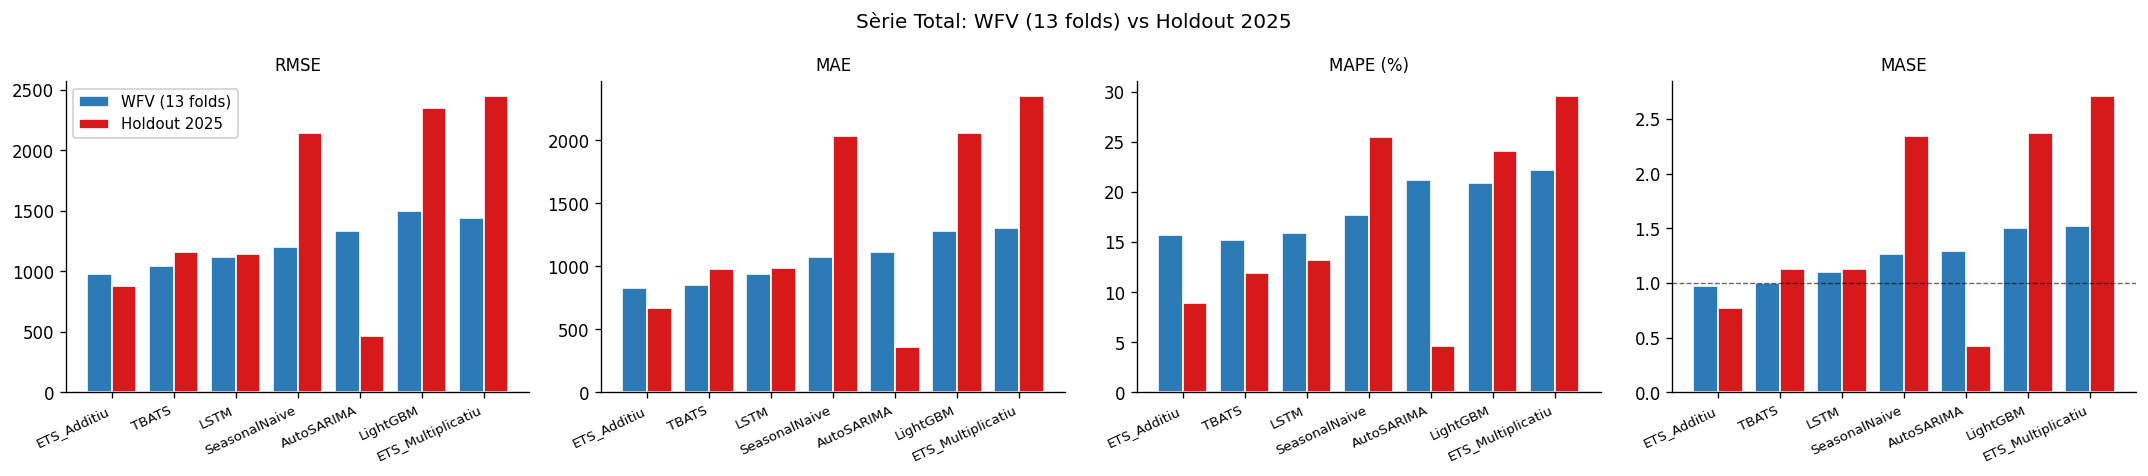

In [8]:
wfv_total = (wfv_metrics_agg[wfv_metrics_agg['Tecnologia'] == 'Total']
             .set_index('Model')[METRICS_4].round(2).sort_values('MASE'))
hold_total = (all_metrics[all_metrics['Tecnologia'] == 'Total']
              .set_index('Model')[METRICS_4].round(2))
print('Rànquing WFV al Total (mitjana de 13 folds per model):')
display(wfv_total)
print('Rànquing holdout 2025 al Total:')
display(hold_total.reindex(wfv_total.index))

# Bar chart al Total: 4 subplots, 2 grups per model (WFV vs holdout)
models_order = wfv_total.index.tolist()
x = np.arange(len(models_order))
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, metric in zip(axes, METRICS_4):
    ax.bar(x - 0.2, wfv_total.loc[models_order, metric].values, width=0.4,
           label='WFV (13 folds)', color='#2c7bb6', edgecolor='white')
    ax.bar(x + 0.2, hold_total.reindex(models_order)[metric].values, width=0.4,
           label='Holdout 2025', color='#d7191c', edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels(models_order, rotation=25, ha='right', fontsize=8)
    ax.set_title(f'{metric}' + (' (%)' if metric == 'MAPE' else ''), fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if metric == 'MASE':
        ax.axhline(1.0, color='black', ls='--', lw=0.8, alpha=0.6)
axes[0].legend(fontsize=9, framealpha=0.9)
plt.suptitle('Sèrie Total: WFV (13 folds) vs Holdout 2025', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_19_wfv_vs_holdout.png', bbox_inches='tight')
plt.show()

### Mètriques WFV per sub-tecnologia (6 sèries)

In [9]:
# Una taula per cada sub-tecnologia (Total ja a 4.1)
for tech in SUB_TECHS:
    sub = (wfv_metrics_agg[wfv_metrics_agg['Tecnologia'] == tech]
           .set_index('Model')[METRICS_4].round(2)
           .sort_values('MASE'))
    if len(sub) == 0:
        continue
    print(f'\n: {tech}:')
    display(sub.style.highlight_min(axis=0, props='font-weight:bold; color:#1a9641'))


: Elèctric:


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,306.670000,257.790000,23.840000,0.720000
LSTM,337.140000,277.930000,23.640000,0.780000
TBATS,337.870000,277.860000,23.550000,0.780000
ETS_Multiplicatiu,348.690000,291.800000,27.340000,0.810000
LightGBM,352.580000,295.100000,24.380000,0.840000
SeasonalNaive,363.660000,300.310000,24.530000,0.850000
AutoSARIMA,450.340000,385.700000,36.730000,1.060000



: Gasolina Mild Hybrid:


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,216.420000,178.240000,11.870000,0.740000
ETS_Multiplicatiu,226.210000,179.990000,11.860000,0.750000
ETS_Additiu,235.530000,194.160000,12.690000,0.800000
TBATS,259.350000,207.930000,13.700000,0.860000
LSTM,319.490000,262.990000,15.980000,1.090000
SeasonalNaive,377.310000,322.810000,19.300000,1.330000
LightGBM,472.190000,407.500000,24.200000,1.680000



: Gasolina/Elèctric:


...

,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,250.500000,209.900000,25.900000,1.690000
LSTM,259.720000,210.260000,25.140000,1.700000
TBATS,268.230000,224.570000,28.020000,1.810000
AutoSARIMA,266.010000,224.450000,28.430000,1.820000
ETS_Multiplicatiu,279.810000,233.730000,28.620000,1.890000
SeasonalNaive,284.670000,233.260000,27.180000,1.890000
LightGBM,293.270000,239.460000,27.740000,1.940000



: Diesel Mild Hybrid:


,RMSE,MAE,MAPE,MASE
Model,,,,
TBATS,51.430000,41.750000,16.410000,0.640000
LSTM,51.780000,42.240000,16.430000,0.650000
ETS_Additiu,53.060000,44.520000,18.060000,0.680000
SeasonalNaive,61.550000,47.510000,17.650000,0.730000
ETS_Multiplicatiu,60.880000,49.120000,18.980000,0.750000
LightGBM,61.400000,49.090000,18.040000,0.750000
AutoSARIMA,60.100000,49.860000,19.730000,0.760000



: Diesel/Elèctric Endollable:


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,12.150000,9.930000,61.880000,1.440000
TBATS,12.740000,10.710000,52.890000,1.540000
LSTM,12.850000,10.930000,55.350000,1.570000
SeasonalNaive,13.920000,11.240000,59.820000,1.630000
AutoSARIMA,15.410000,12.270000,83.880000,1.790000
LightGBM,15.530000,13.090000,63.400000,1.860000
ETS_Multiplicatiu,20.120000,15.400000,79.770000,2.160000


### Variabilitat de l'error entre folds (boxplot)

Separem el Total de les 6 sub-tecnologies per no barrejar nivells jeràrquics. El panel esquerre mostra la distribució del MASE sobre els 13 folds de la sèrie Total per cada model; el dret, sobre els 78 folds (6 sub-tecnologies × 13 folds) per cada model.

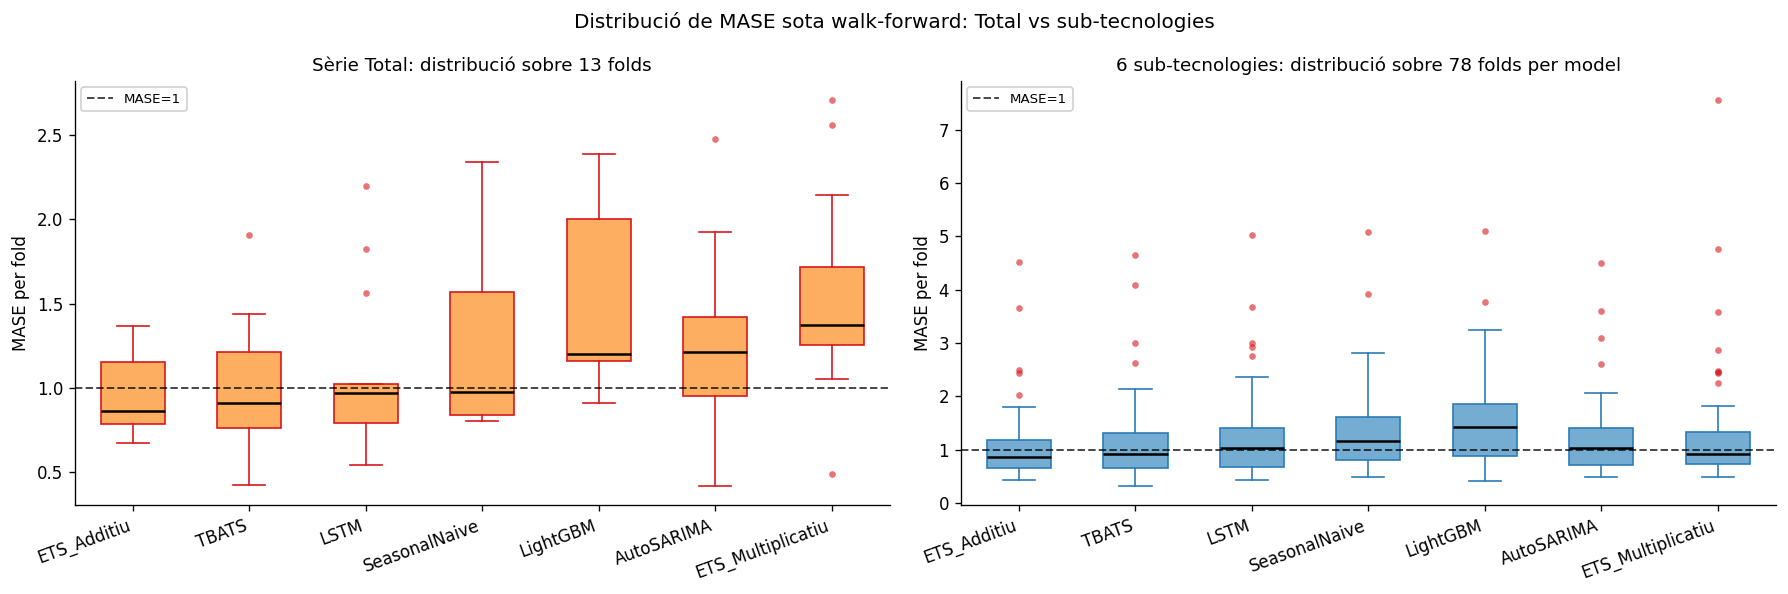

Total — estadístiques MASE (13 folds per model):


,median,mean,std,pct_<1
Model,,,,
ETS_Additiu,0.86,0.97,0.24,53.85
TBATS,0.91,1.00,0.41,53.85
LSTM,0.97,1.10,0.47,61.54
SeasonalNaive,0.98,1.26,0.57,53.85
LightGBM,1.20,1.50,0.56,15.38
AutoSARIMA,1.21,1.29,0.51,30.77
ETS_Multiplicatiu,1.38,1.52,0.62,7.69


Sub-tecnologies — estadístiques MASE (78 folds per model):


,median,mean,std,pct_<1
Model,,,,
ETS_Additiu,0.86,1.05,0.66,60.26
ETS_Multiplicatiu,0.92,1.22,1.02,53.85
TBATS,0.93,1.12,0.74,58.97
LSTM,1.02,1.20,0.78,47.44
AutoSARIMA,1.03,1.19,0.69,46.15
SeasonalNaive,1.17,1.31,0.73,37.18
LightGBM,1.43,1.47,0.82,34.62


In [10]:
total_data = wfv_metrics[wfv_metrics['Tecnologia'] == 'Total']
subtech_data = wfv_metrics[wfv_metrics['Tecnologia'] != 'Total']

# Ordre per mediana al Total (que és la pregunta principal)
order_box = total_data.groupby('Model')['MASE'].median().sort_values().index.tolist()
positions = np.arange(len(order_box))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)

# Subplot 1: Total (13 folds per model)
ax = axes[0]
data_tot = [total_data[total_data['Model'] == m]['MASE'].values for m in order_box]
ax.boxplot(data_tot, positions=positions, widths=0.55, patch_artist=True,
           medianprops=dict(color='black', lw=1.5),
           boxprops=dict(facecolor='#fdae61', edgecolor='#d7191c'),
           whiskerprops=dict(color='#d7191c'),
           capprops=dict(color='#d7191c'),
           flierprops=dict(marker='o', markersize=4, markerfacecolor='#d7191c',
                           markeredgecolor='none', alpha=0.6))
ax.axhline(1.0, color='black', ls='--', lw=1.2, alpha=0.7, label='MASE=1')
ax.set_xticks(positions)
ax.set_xticklabels(order_box, rotation=20, ha='right')
ax.set_ylabel('MASE per fold')
ax.set_title('Sèrie Total: distribució sobre 13 folds', fontsize=11)
ax.legend(fontsize=8, framealpha=0.9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Subplot 2: 6 sub-tecnologies (78 folds per model)
ax = axes[1]
data_sub = [subtech_data[subtech_data['Model'] == m]['MASE'].values for m in order_box]
ax.boxplot(data_sub, positions=positions, widths=0.55, patch_artist=True,
           medianprops=dict(color='black', lw=1.5),
           boxprops=dict(facecolor='#74add1', edgecolor='#2c7bb6'),
           whiskerprops=dict(color='#2c7bb6'),
           capprops=dict(color='#2c7bb6'),
           flierprops=dict(marker='o', markersize=4, markerfacecolor='#d7191c',
                           markeredgecolor='none', alpha=0.6))
ax.axhline(1.0, color='black', ls='--', lw=1.2, alpha=0.7, label='MASE=1')
ax.set_xticks(positions)
ax.set_xticklabels(order_box, rotation=20, ha='right')
ax.set_ylabel('MASE per fold')
ax.set_title('6 sub-tecnologies: distribució sobre 78 folds per model', fontsize=11)
ax.legend(fontsize=8, framealpha=0.9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.suptitle('Distribució de MASE sota walk-forward: Total vs sub-tecnologies', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_20_wfv_boxplot.png', bbox_inches='tight')
plt.show()

# Estadístiques de dispersió: Total
disp_tot = (total_data.groupby('Model')['MASE']
            .agg(['median', 'mean', 'std', ('pct_<1', lambda x: (x < 1.0).mean() * 100)])
            .round(2).sort_values('median'))
print('Total — estadístiques MASE (13 folds per model):')
display(disp_tot)

# Estadístiques de dispersió: sub-techs
disp_sub = (subtech_data.groupby('Model')['MASE']
            .agg(['median', 'mean', 'std', ('pct_<1', lambda x: (x < 1.0).mean() * 100)])
            .round(2).sort_values('median'))
print('Sub-tecnologies — estadístiques MASE (78 folds per model):')
display(disp_sub)

### Sèries h=1 per sub-tecnologia (tots els models)

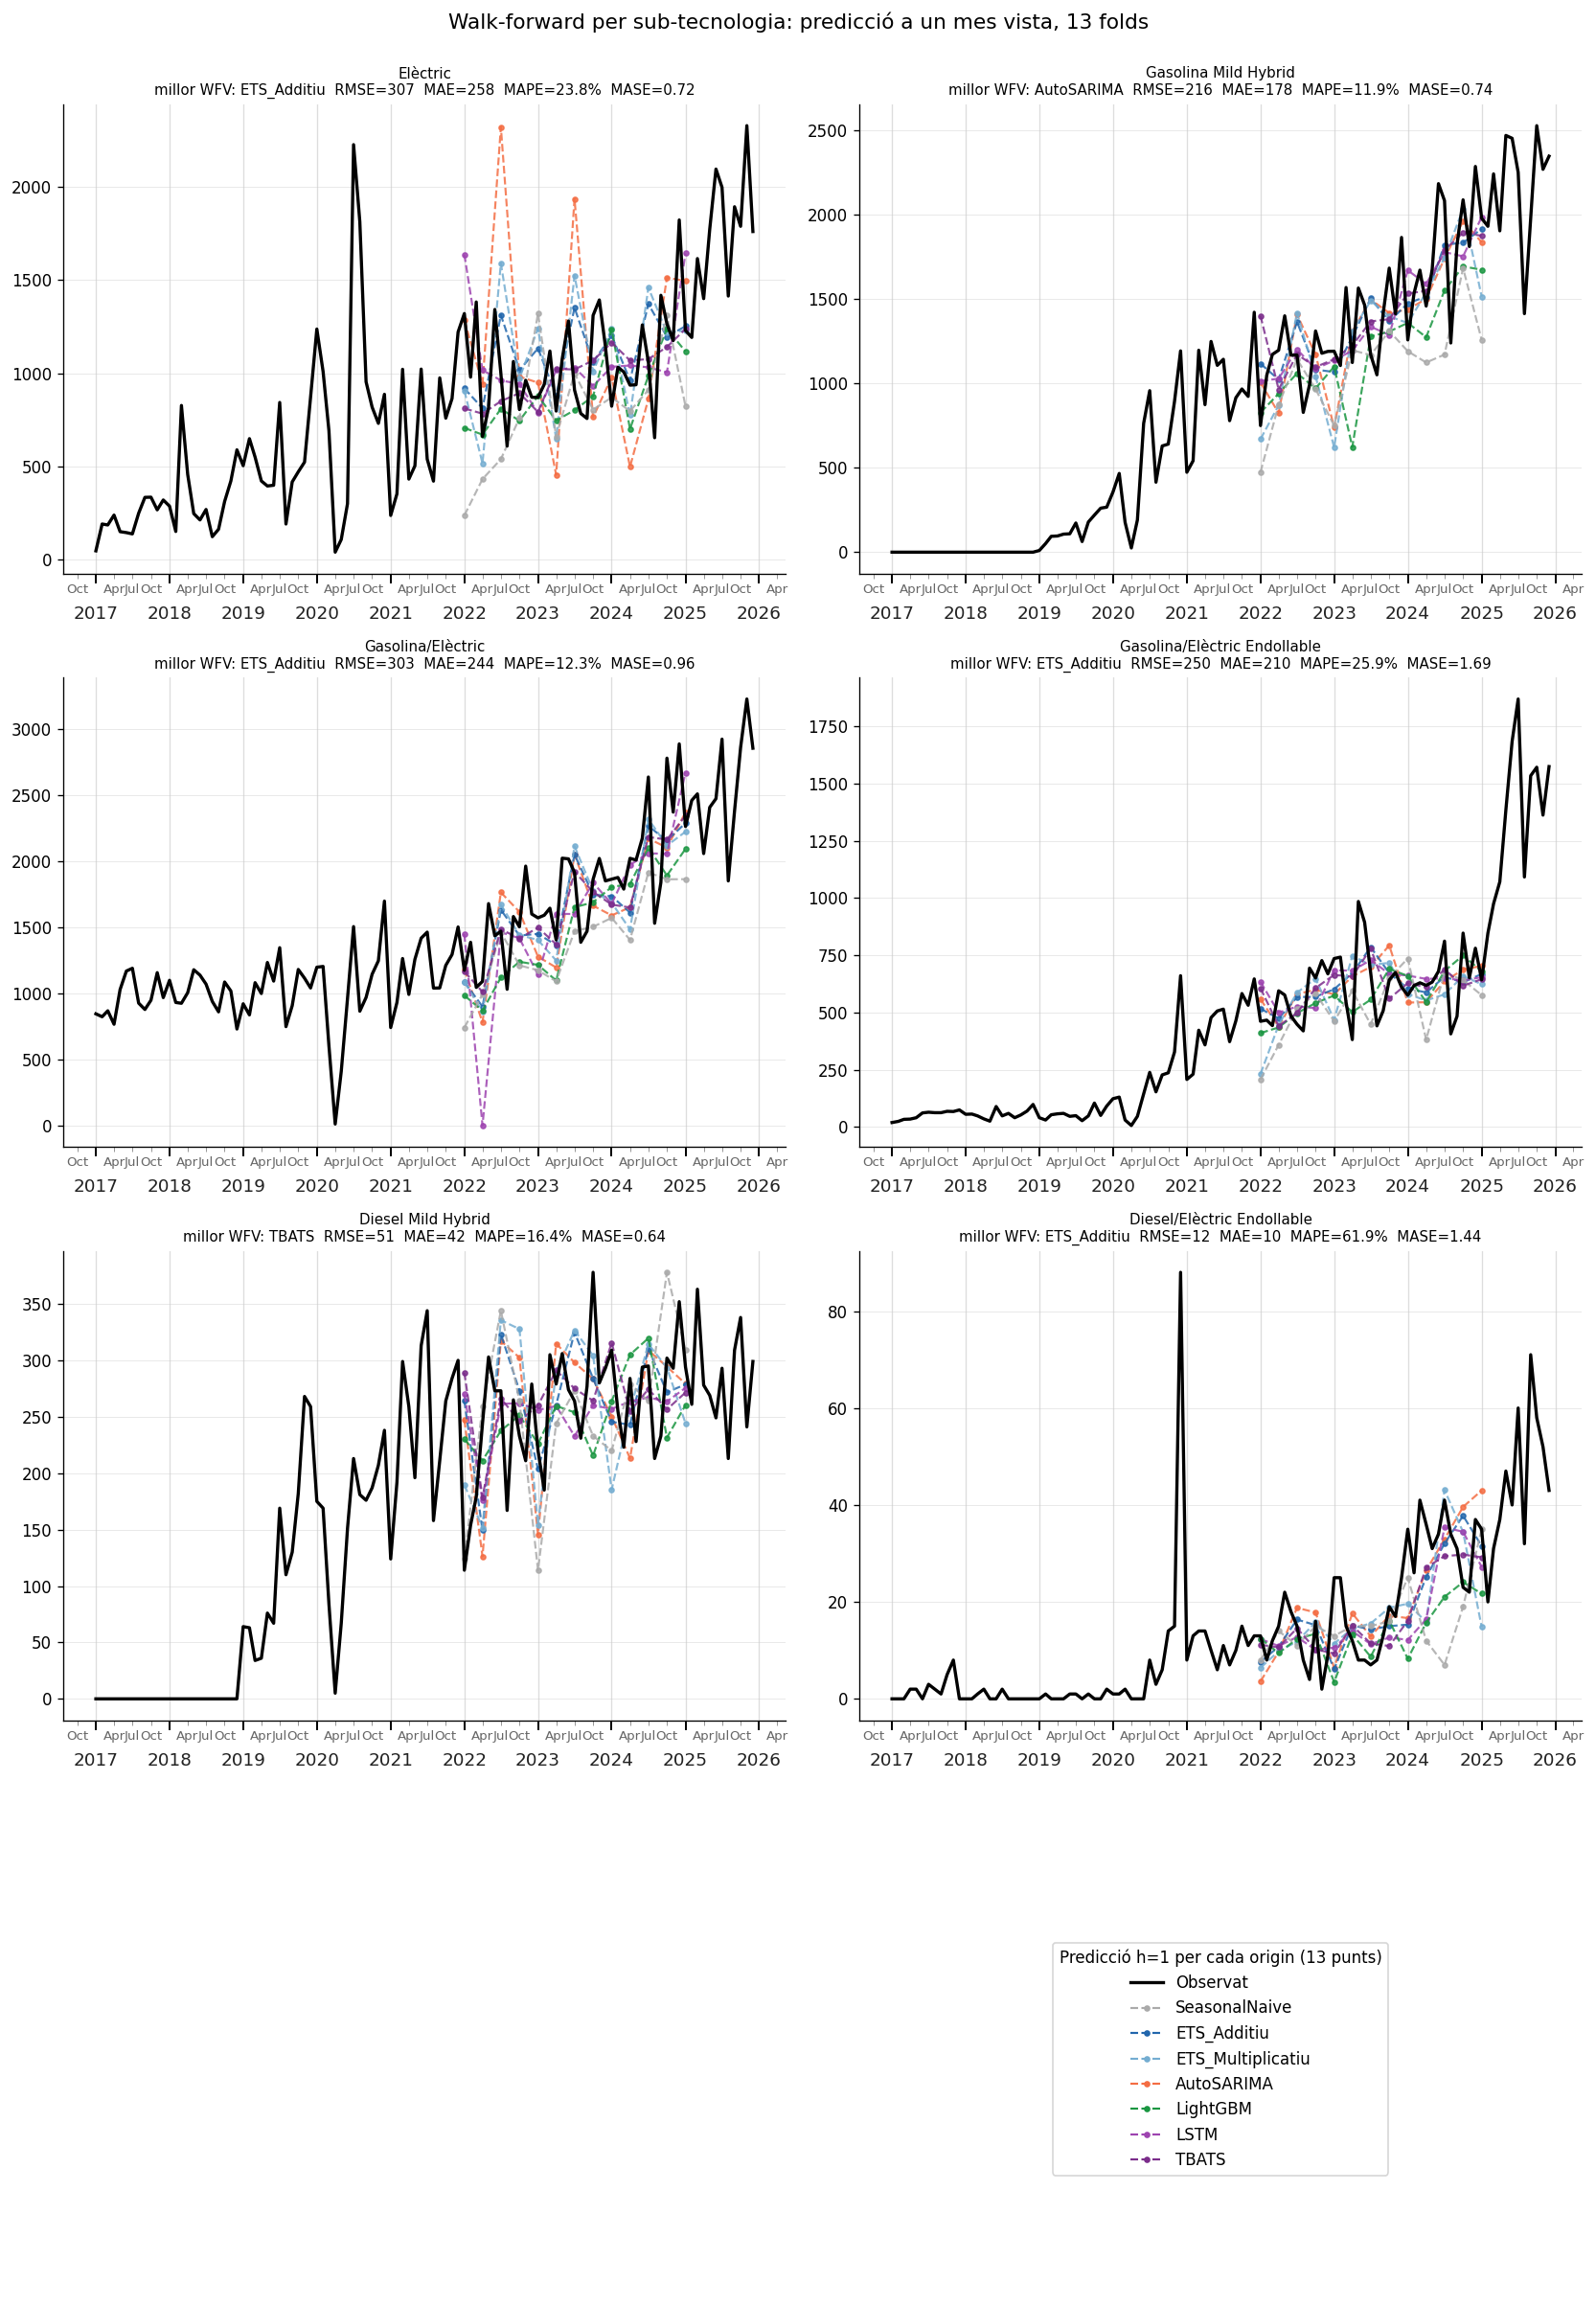

In [11]:
pivot_full_ev = pd.concat([pivot_train_ev, pivot_test_ev]).sort_index()

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes_flat = axes.flatten()

for i, tech in enumerate(SUB_TECHS):
    ax = axes_flat[i]
    s = pivot_full_ev[tech]
    ax.plot(s.index, s.values, color='black', lw=2, zorder=10)

    sub = wfv_forecasts_raw[
        (wfv_forecasts_raw['Tecnologia'] == tech)
        & (wfv_forecasts_raw['h'] == 1)
    ]
    for model_name in sorted(sub['Model'].unique()):
        msub = sub[sub['Model'] == model_name].sort_values('date')
        ax.plot(pd.to_datetime(msub['date']), msub['predicted'],
                color=palette.get(model_name, '#888888'),
                lw=1.3, ls='--', marker='o', ms=3, alpha=0.85)

    best = (wfv_metrics_agg[wfv_metrics_agg['Tecnologia'] == tech]
            .sort_values('MASE').iloc[0])
    ax.set_title(
        f'{tech}\nmillor WFV: {best["Model"]}  RMSE={best["RMSE"]:.0f}  '
        f'MAE={best["MAE"]:.0f}  MAPE={best["MAPE"]:.1f}%  MASE={best["MASE"]:.2f}',
        fontsize=9)
    format_ts_ax(ax)

# Panells no usats (legend al darrer)
for j in range(len(SUB_TECHS), len(axes_flat)):
    axes_flat[j].axis('off')
legend = [Line2D([0], [0], color='black', lw=2, label='Observat')]
for model_name, c in palette.items():
    if model_name in wfv_metrics_agg['Model'].unique():
        legend.append(Line2D([0], [0], color=c, lw=1.3, ls='--', marker='o',
                             ms=3, label=model_name))
axes_flat[-1].legend(handles=legend, loc='center', fontsize=10,
                     title='Predicció h=1 per cada origin (13 punts)')

plt.suptitle('Walk-forward per sub-tecnologia: predicció a un mes vista, 13 folds',
             fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_21_wfv_series_per_tech.png', bbox_inches='tight')
plt.show()

In [12]:
ranking_total.reset_index().to_csv(RESULTS_DIR / 'model_ranking_total.csv', index=False)
all_metrics.to_csv(RESULTS_DIR / 'all_metrics.csv', index=False)
wfv_metrics.to_csv(RESULTS_DIR / 'all_wfv_metrics.csv', index=False)
wfv_metrics_agg.to_csv(RESULTS_DIR / 'all_wfv_metrics_agg.csv', index=False)
print('Guardats: model_ranking_total.csv, all_metrics.csv, all_wfv_metrics.csv, all_wfv_metrics_agg.csv')

Guardats: model_ranking_total.csv, all_metrics.csv, all_wfv_metrics.csv, all_wfv_metrics_agg.csv


## 5. Conclusions

Aquest projecte estableix un benchmark reproduïble per al forecasting de matriculacions de vehicles electrificats i híbrids a Catalunya entre 2017 i 2025. Hem comparat set models de tres famílies (baselines, estadístics clàssics i machine learning) sobre set sèries (sis tecnologies més el Total agregat), amb dues avaluacions complementàries: un holdout únic sobre el 2025 i un walk-forward amb 13 origins. El fil que articula tot el treball és la connexió entre les troballes de l'EDA, les decisions de modelització i els resultats finals. Reportem les mètriques separant explícitament el Total (la pregunta principal: matriculacions agregades) de les sis sub-tecnologies (anàlisi diagnòstica per dinàmica), sense fer cap mitjana entre nivells jeràrquics.

**Resultat principal — sèrie Total**: AutoSARIMA guanya el holdout 2025 amb MASE 0.42, seguit d'ETS Additiu (0.77). Tots dos entrenen sobre el logaritme del Total, la transformació recomanada per l'EDA amb BoxCox λ≈0.49 per estabilitzar la variança creixent de l'agregat. La diferència respecte als models que treballen en nivell (TBATS i LSTM a 1.13, Seasonal Naive a 2.34) demostra que en aquesta sèrie l'escala de modelització importa més que la família del model. Sota walk-forward (13 origins, 12 mesos per fold), però, el rànquing es reordena: ETS Additiu lidera amb MASE mig 0.97 i AutoSARIMA cau al cinquè lloc (1.29). Aquesta divergència és la lliçó metodològica clau: un holdout únic captura un punt de l'espai temporal i pot premiar un model adaptat a les peculiaritats d'aquell any (aquí, AutoSARIMA al 2025), mentre que el WFV revela la robustesa al llarg del temps.

**Per tecnologia**: cap model guanya a totes les sèries, i això és exactament el que esperem. ETS Multiplicatiu encerta a Elèctric i Gasolina/Elèctric (estacionalitat creixent amb el nivell, un patró que l'EDA ja documentava). AutoSARIMA domina Gasolina Mild Hybrid i Diesel/Elèctric Endollable (dinàmica més estable). Una advertència important: amb només 12 observacions de test per holdout, les diferències petites no són estadísticament distingibles. A Diesel Mild Hybrid LSTM (0.53), TBATS (0.54) i AutoSARIMA (0.56) són empat efectiu; a Gasolina/Elèctric AutoSARIMA i ETS Additiu empaten també (0.60). La lectura honesta no és "el millor model per cada tecnologia" sinó "quines famílies de models s'ajusten a cada tipus de dinàmica".

**Límits del benchmark**: dos punts. Primer, amb N≈84 mostres de train i una estacionalitat anual neta, els estadístics clàssics superen el machine learning, replicant Makridakis et al. (2020). LightGBM tanca el rànquing del Total amb MASE 2.37 i LSTM és mediocre malgrat la seva flexibilitat. Segon, el creixement del +34% YoY al 2025 (front al +17% històric documentat a l'EDA) reflecteix una acceleració estructural del mercat que cap sèrie univariant pot anticipar. Els drivers (xarxa de càrrega, preus dels EV, política industrial) són exògens al senyal històric.

**El cas extrem és el PHEV (Gasolina/Elèctric Endollable)**. Tots els models tenen MASE entre 4.50 i 5.10. La seva dinàmica no depèn només de l'existència del MOVES III, que ja portava quatre anys actiu, sinó del **règim regulatori canviant del programa**: pròrrogues, ampliacions pressupostàries i efectes de data límit. El plateau del 2024 (−1%) coincideix amb la incertesa sobre la pròrroga del pla, que originalment vencia el 31 de desembre de 2024. El salt del +101.7% al 2025 s'explica per una combinació de factors regulatius: la pròrroga aprovada per Reial Decret-llei a l'abril amb efecte retroactiu des de gener, l'ampliació pressupostària a 800 milions d'euros, els ajuts directes de fins a 4.500€ per PHEV, la deducció del 15% a l'IRPF, i l'efecte de la data límit del 31 de desembre que va resoldre massivament les sol·licituds pendents. Cap d'aquests senyals existeix a la sèrie temporal univariant; són exclusivament regulatoris.

**Línia natural de continuïtat**: incorporar variables exògenes per fer el benchmark predictiu de canvis estructurals i no només descriptiu de la dinàmica històrica. L'experiment més concret i acotat és SARIMAX sobre Gasolina/Elèctric Endollable amb dos indicadors binaris (data límit 31-des-2024, vigència del Reial Decret-llei d'abril 2025); això respon directament la pregunta que aquest benchmark deixa oberta. Per al Total, regressors d'infraestructura de càrrega i preus dels EV permetrien capturar l'acceleració estructural del 2025. Opcionalment, un pas de reconciliació jeràrquica garantiria que les prediccions per tecnologia sumin coherentment al Total. Amb aquestes extensions, el projecte passaria de respondre què diuen les dades sobre el passat a anticipar canvis impulsats per polítiques i mercat.